### 08. Прогностическая модель: Что на самом деле определяет высокую оценку?

Какие факторы (привычки и характеристики) оказывают наибольшее влияние на вероятность получения 80+ баллов на экзамене? Можно ли с помощью ML-модели (Decision Tree) выделить критический порог поведения, после которого студент гарантированно попадает в группу успешных? 

In [17]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

from src.preparation import load_df
df = load_df()

Показатель точности: 0.85

Отчет о классификации:
              precision    recall  f1-score   support

       False       0.92      0.87      0.89       145
        True       0.70      0.80      0.75        55

    accuracy                           0.85       200
   macro avg       0.81      0.83      0.82       200
weighted avg       0.86      0.85      0.85       200


Матрица ошибок:
[[126  19]
 [ 11  44]]

Важность признаков:
study_hours_per_day: 0.76862
social_media_hours: 0.03882
sleep_hours: 0.01145
exercise_frequency: 0.03400
mental_health_rating: 0.14709
NB! Все остальные признаки (age, netflix_hours, attendance_percentage, gender_female, gender_male, gender_other, part_time_job_no, part_time_job_yes, diet_quality_fair, diet_quality_good, diet_quality_poor, parental_education_level_bachelor, parental_education_level_high school, parental_education_level_master, internet_quality_average, internet_quality_good, internet_quality_poor, extracurricular_participation_no, extracu

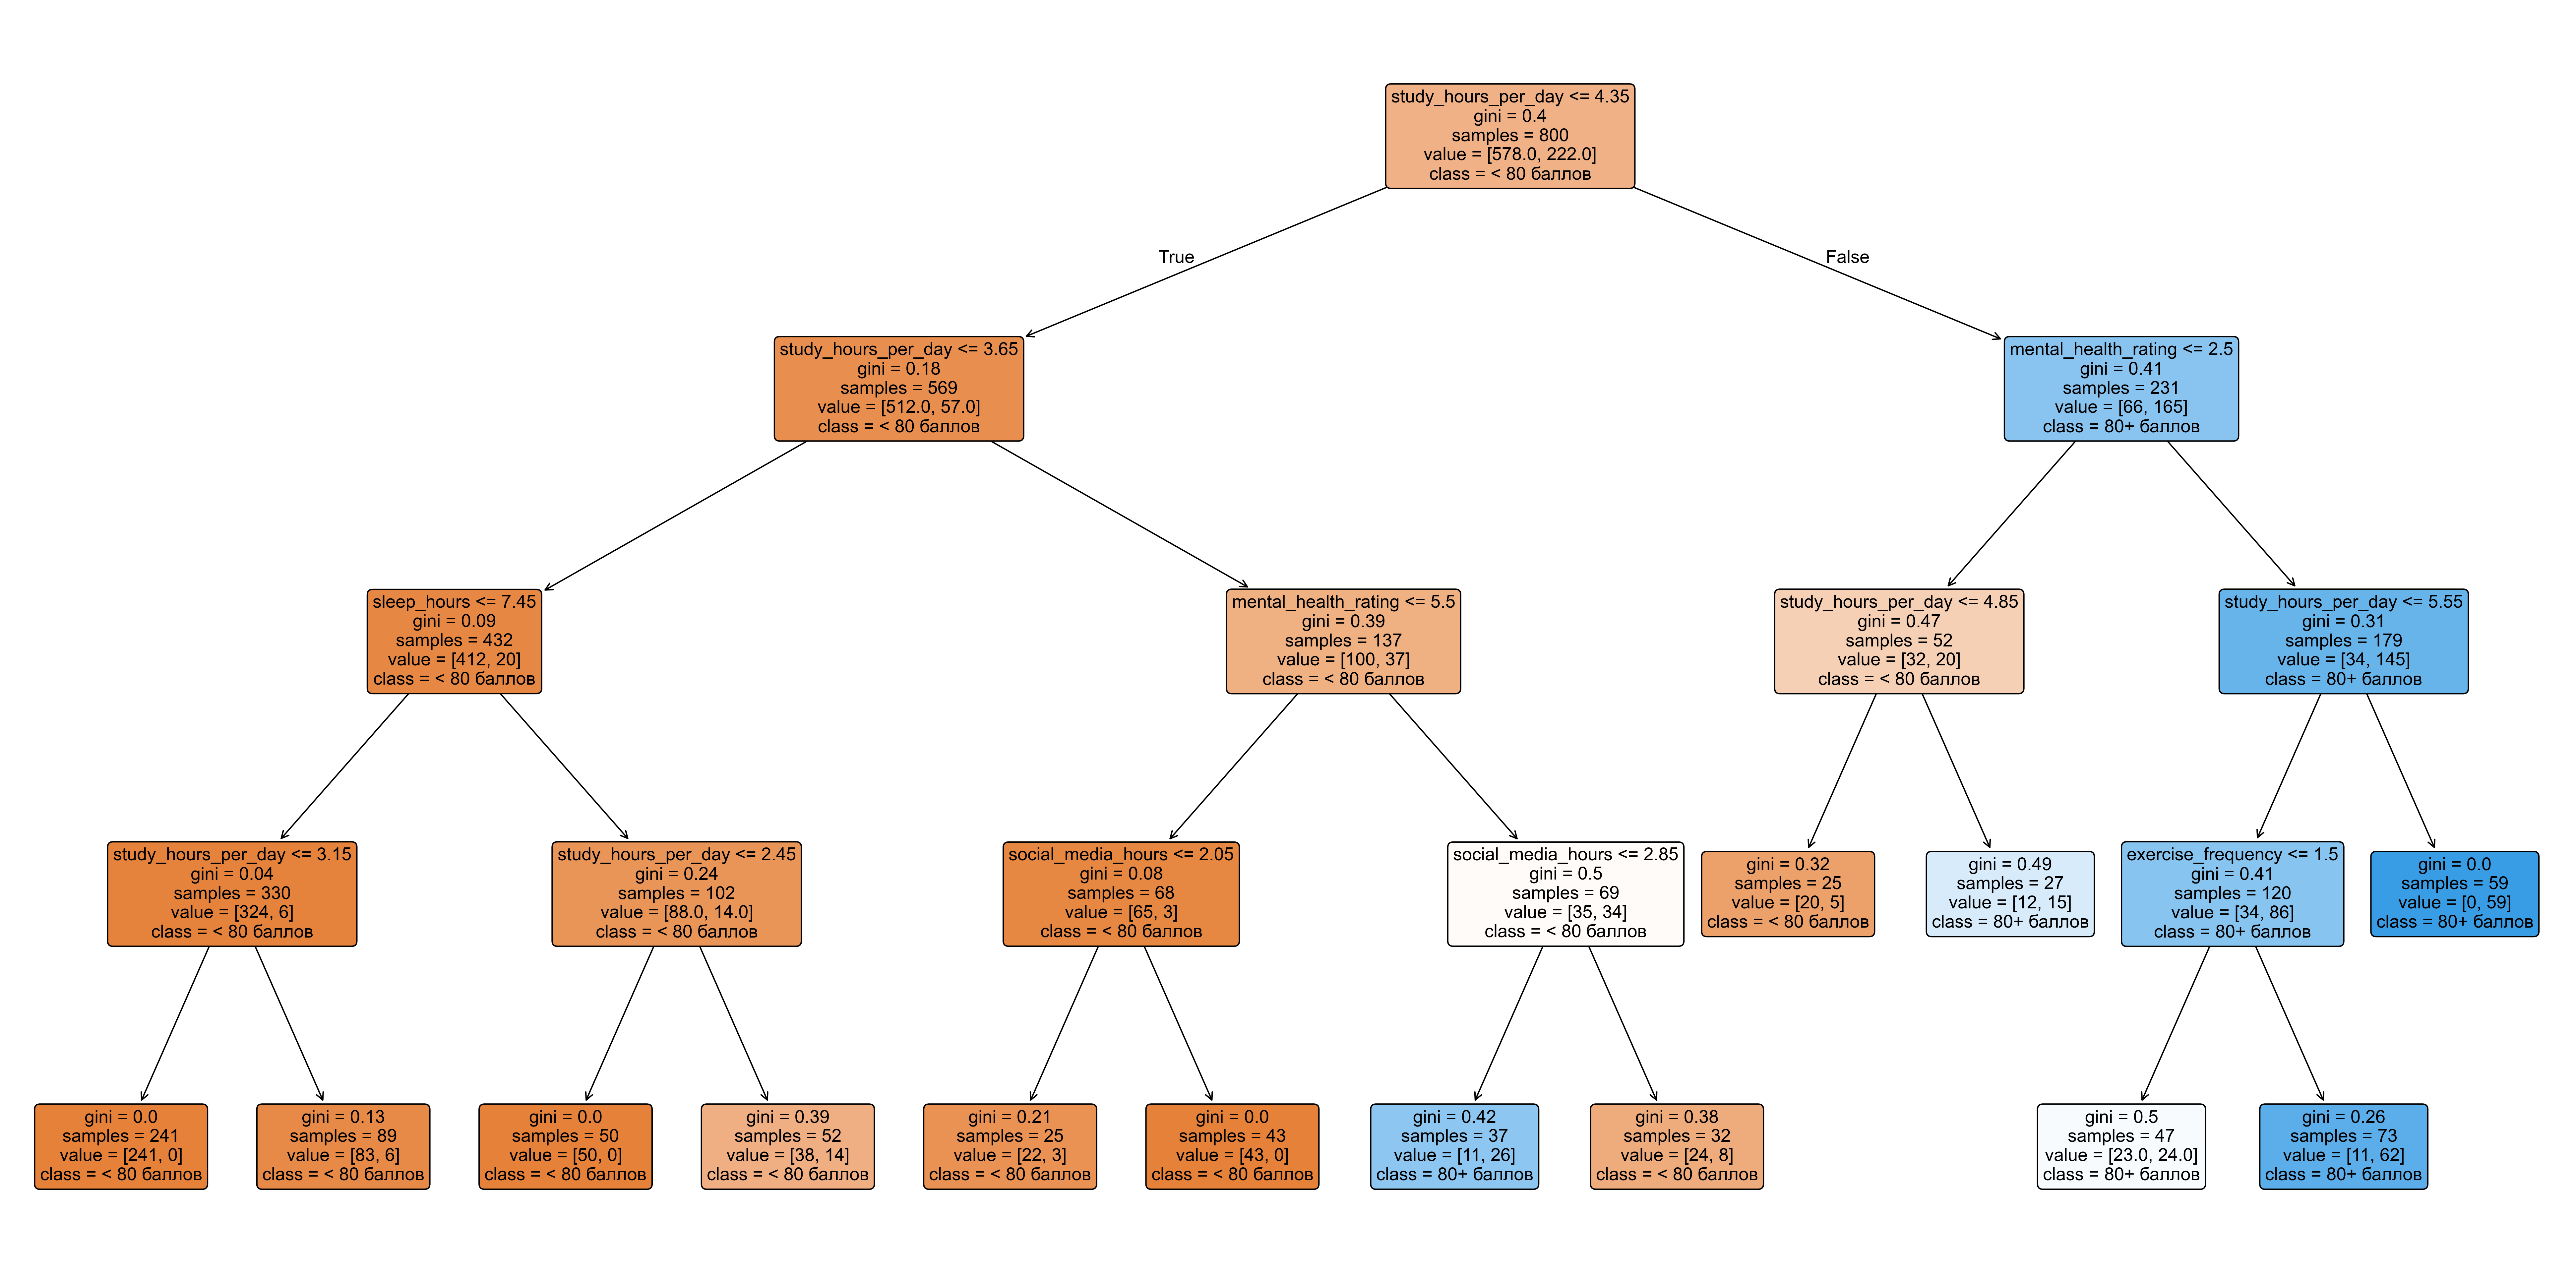

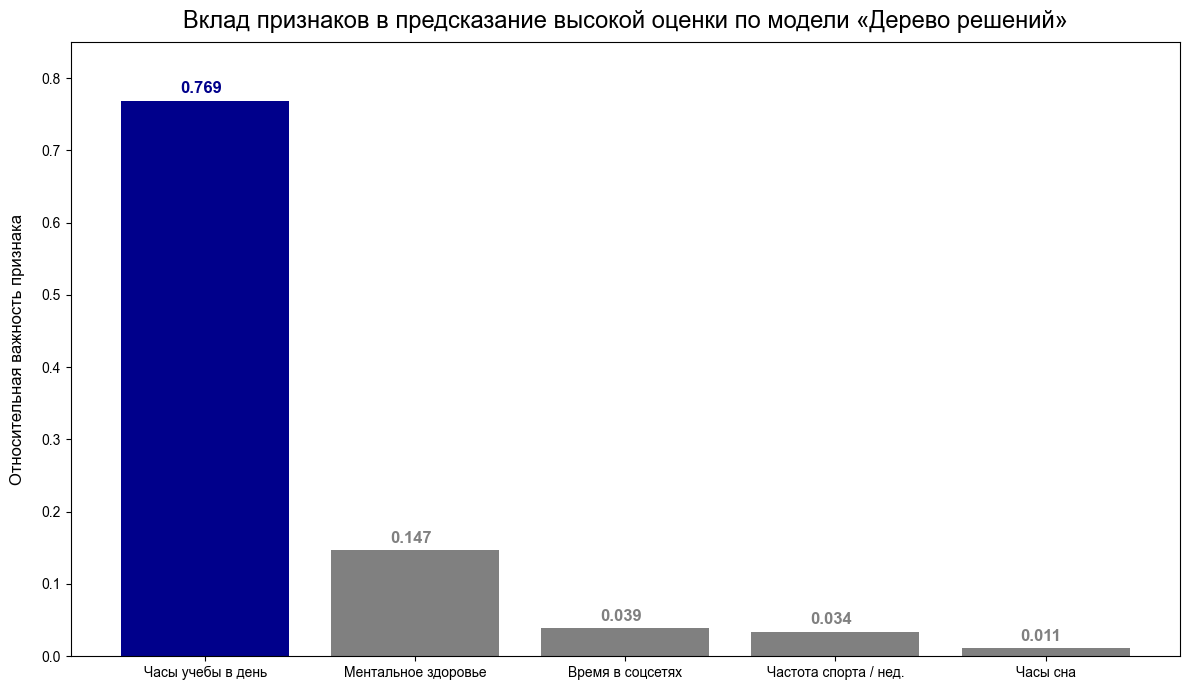

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import src.constants as cnst
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.rcParams['font.family'] = 'Arial'

df_02_08 = df.copy()

# целевая переменная 
df_02_08['is_high_score'] = df_02_08.exam_score >= 80

bin = pd.get_dummies(df_02_08.drop(columns=['student_id', 'exam_score', 'is_high_score']))  # ? NaN-значения только в одном столбце про образование родителей, не вижу смысла тут dummy_na=True
tgt = df_02_08['is_high_score']

X_train, X_test, y_train, y_test = train_test_split(bin, tgt, test_size=.2, random_state=42, stratify=tgt)
mdl = DecisionTreeClassifier(max_depth=4, random_state=42, min_samples_leaf=25)
mdl.fit(X_train, y_train)

y_pred = mdl.predict(X_test)
print(f'Показатель точности: {accuracy_score(y_test, y_pred)}')

print('\nОтчет о классификации:')
print(classification_report(y_test, y_pred))

print('\nМатрица ошибок:')
print(confusion_matrix(y_test, y_pred))

print('\nВажность признаков:')
null_imp = []
for f, imp in dict(zip(X_test.columns, (imps := mdl.feature_importances_))).items():
    if imp > 0: 
        print(f'{f}: {imp:.5f}')
    else: 
        null_imp.append(f.lower())
print(f'NB! Все остальные признаки ({", ".join(null_imp)}) имеют нулевую важность.')
    
    
plt.figure(figsize=(26, 13), dpi=300)

plot_tree(
    mdl, 
    feature_names=X_test.columns, class_names=['< 80 баллов', '80+ баллов'], 
    filled=True, rounded=True, precision=2, fontsize=13, impurity=True
)

plt.tight_layout()


fig, ax = plt.subplots(figsize=(12, 7))

df_imps = pd.DataFrame({
    'feature': X_test.columns, 
    'importance': imps 
})
df_imps = df_imps.loc[df_imps.importance > 0].sort_values('importance', ascending=False).set_index('feature')

colors = ['darkblue' if i == 0 else 'grey' for i in range(len(df_imps))]
ax.bar(df_imps.index, df_imps.importance, color=colors)

ax.set_ylim(0, .85)

for i, (lbl, val) in enumerate(df_imps.iterrows()): 
    ax.annotate(
        text=f'{val.values[0]:.3f}', 
        xy=(i -.12, val.values[0] + .01), 
        fontsize=12, color = 'grey' if i != 0 else 'darkblue', fontweight='bold'
        )
    
ax.set_xticks(range(len(df_imps)))
ax.set_xticklabels(['Часы учебы в день', 'Ментальное здоровье', 'Время в соцсетях', 'Частота спорта / нед.', 'Часы сна'])
ax.set_title('Вклад признаков в предсказание высокой оценки по модели «Дерево решений»', **cnst.TITLE_PARAMS)
ax.set_ylabel('Относительная важность признака', **cnst.LABEL_PARAMS)

plt.tight_layout()

#### 08. Выводы

Построенная модель дерева решений (Decision Tree) с точностью **85%** на тестовой выборке позволила выявить факторы, определяющие успех на экзамене. 

***1. Учёба — абсолютный доминант.***
Анализ важности признаков (Feature Importance) показал, что количество часов учёбы в день определяет **76.9%** успеха. Это означает, что без достаточной учебной нагрузки остальные привычки практически не имеют значения. 

***2. Критический порог.***
Дерево решений выявило четкую точку перелома: **4.3 часа учёбы в день**. Если студент учится меньше этого времени, модель практически гарантированно относит его к группе с оценкой < 80 баллов, независимо от его сна или ментального здоровья. 

***3. Роль остальных факторов.***
Ментальное здоровье занимает второе место по важности (14.7%). Оно становится решающим фактором для тех, кто уже перешагнул порог в 4.3 часа. Влияние социальных сетей (3.9%), спорта (3.4%) и сна (1.1%) в данной модели оказалось минимальным — на фоне учёбы эти факторы не являются определяющими.

**Ограничения модели:** Дерево решений склонно к пороговым эффектам (все или ничего), а признаки, формирующие оценку напрямую (сам балл), были исключены из обучения во избежание утечки данных. Тем не менее, модель подтвердила главную гипотезу исследования: **фундаментом успеха являются академические усилия.**